# *1. Import libraries*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


pd.set_option("display.max_columns", 120)

In [2]:
%%capture
!pip install catboost

In [3]:
%%capture
!pip install shap

# *2. Load the data*

In [4]:
from pathlib import Path

PATH = Path.cwd() / "telecom"
client_path = PATH / "Client.csv"
record_path = PATH / "Record.csv"

for p in (client_path, record_path):
    print(f"{'OK     ' if p.exists() else 'MISSING'} {p}")

OK      /content/telecom/Client.csv
OK      /content/telecom/Record.csv


In [5]:
client = pd.read_csv(client_path)
record = pd.read_csv(record_path)

print(f"Client: {client.shape}")
print(f"Record: {record.shape}")

Client: (100000, 50)
Record: (100000, 51)


In [6]:
# Merge on Customer_ID. Both tables have one row per customer, so this is a 1:1 join.
df = record.merge(client, on='Customer_ID', how='inner')
print(f"Merged: {df.shape}")
df.head()

Merged: (100000, 100)


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.000000,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.000000,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.000000,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,0.0000,0.000000,0.0,0.000000,0.0,0.000000,0.0,3.666667,0.0,1.333333,0.0,3.666667,0.0,0.000000,0.000000,0.000000,1.333333,0.000000,8.410000,0.0,0.413333,0.333333,0.256667,0.000000,0.000000,1.333333,0.0,3.380000,0.0,3.666667,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60,1000004,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,1479,40.45,63.23,30.81,8,3,38,50.0,25.0,40.0,T,CHICAGO AREA,N,N,29.98999,1.0,1.0,NaN,0.0,0.0,NaN,6.0,M,M,4.0,M,6.0,1.0,C,D,0.0,U,Y,U,U,U,U,Y,1812.0
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,0.0000,9.666667,0.0,0.666667,0.0,77.000000,0.0,222.333333,0.0,94.666667,0.0,137.000000,0.0,8.666667,15.000000,11.076667,66.000000,0.000000,285.233333,0.0,106.330000,14.666667,10.816667,0.666667,0.366667,97.333333,0.0,173.476667,0.0,90.333333,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57,1000005,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,4452,38.69,249.38,79.50,558,191,55,586.0,196.0,80.0,U,NEW ENGLAND AREA,Y,N,149.98999,6.0,4.0,WCMB,0.0,0.0,R,5.0,M,S,1.0,M,6.0,1.0,C,O,0.0,I,U,U,U,U,U,Y,434.0


# *3. Exploratory Data Analysis*

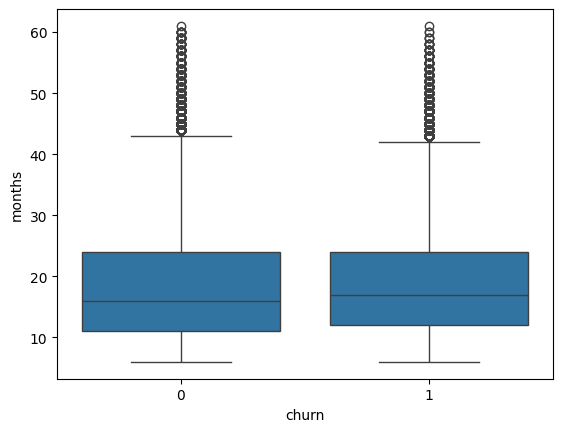

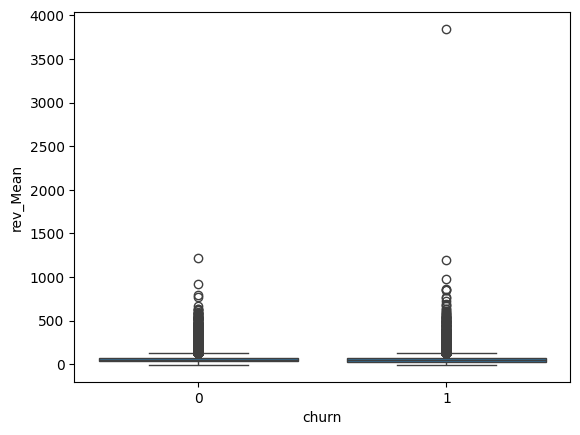

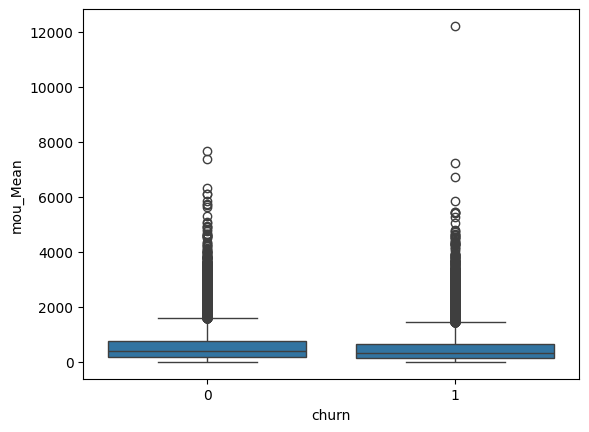

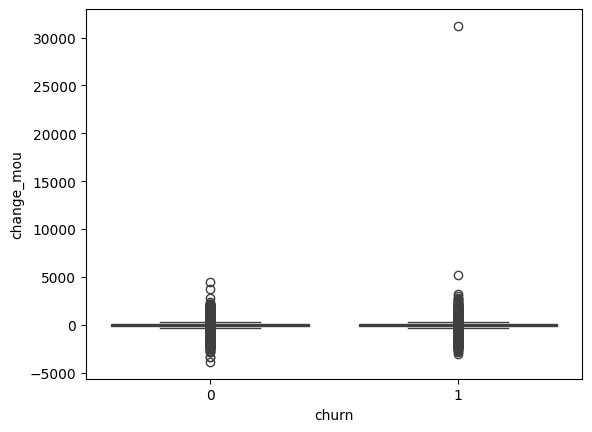

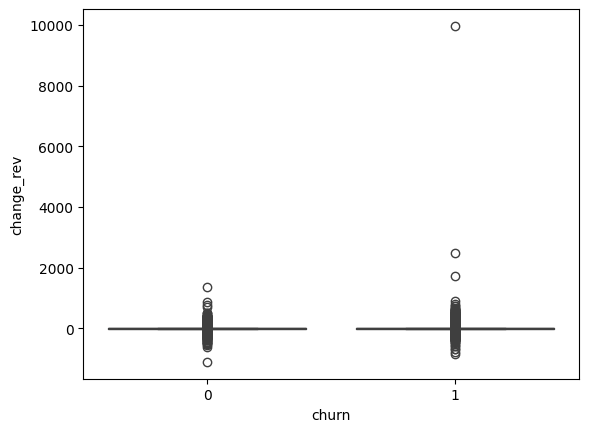

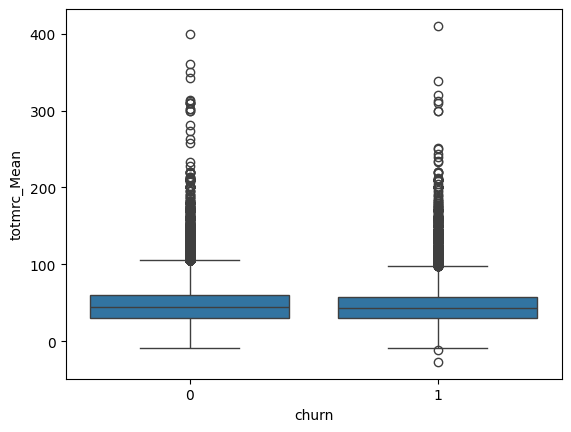

In [7]:
cols_to_look = ["months", "rev_Mean", "mou_Mean", "change_mou", "change_rev", "totmrc_Mean"]

for feature in cols_to_look:

  sns.boxplot(data=df, x="churn", y=feature)
  plt.show()

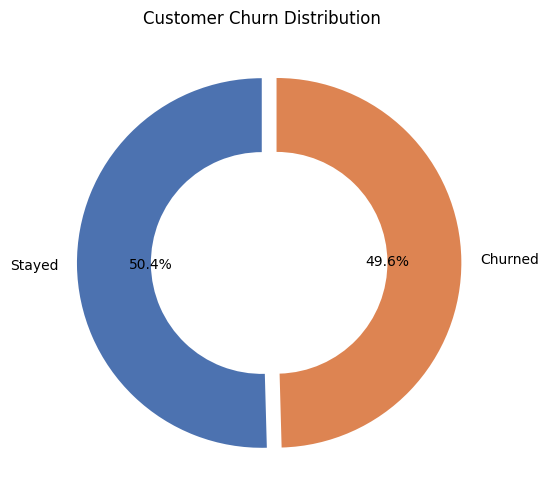

In [8]:
churn_counts = df["churn"].value_counts()
plt.figure(figsize=(6,6))

plt.pie(
    churn_counts,
    labels=["Stayed", "Churned"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#4C72B0", "#DD8452"],
    wedgeprops={"width": 0.4},
    explode=(0, 0.08)
)

plt.title("Customer Churn Distribution")

plt.show()

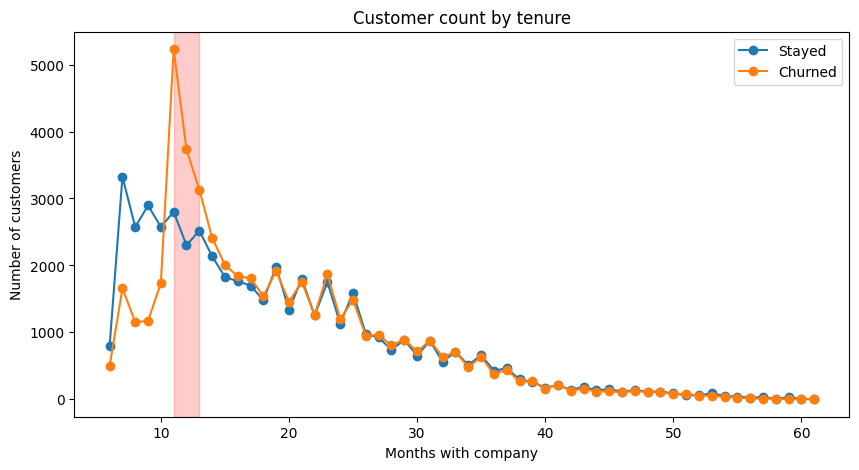

In [9]:
stayed_counts = df[df['churn']==0]['months'].value_counts().sort_index()
churned_counts = df[df['churn']==1]['months'].value_counts().sort_index()

plt.figure(figsize=(10,5))

plt.plot(stayed_counts.index, stayed_counts.values,
         marker='o', label='Stayed')

plt.plot(churned_counts.index, churned_counts.values,
         marker='o', label='Churned')

plt.axvspan(11, 13, color='red', alpha=0.2)

plt.xlabel('Months with company')
plt.ylabel('Number of customers')
plt.title('Customer count by tenure')
plt.legend()

plt.show()

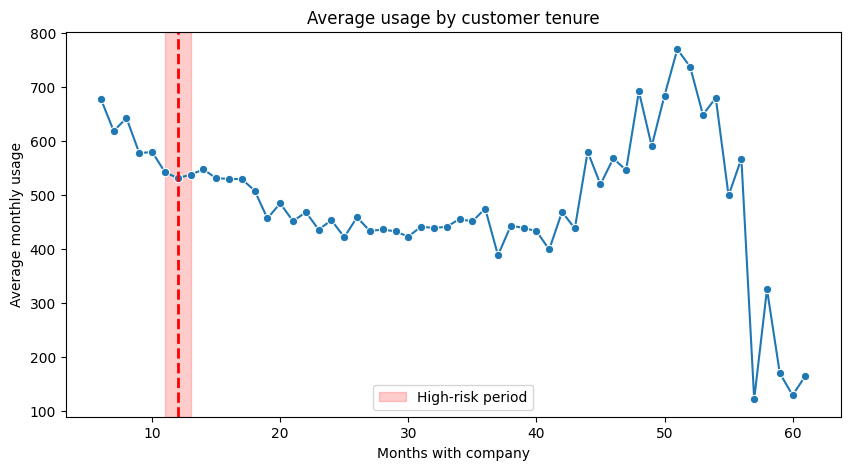

In [10]:
usage_by_month = (
    df.groupby("months")["mou_Mean"]
      .mean()
)

plt.figure(figsize=(10,5))

sns.lineplot(
    x=usage_by_month.index,
    y=usage_by_month.values,
    marker="o"
)

plt.axvspan(
    11, 13,
    color='red',
    alpha=0.2,
    label='High-risk period'
)

plt.axvline(
    x=12,
    color='red',
    linestyle='--',
    linewidth=2
)

plt.xlabel("Months with company")
plt.ylabel("Average monthly usage")
plt.title("Average usage by customer tenure")
plt.legend()

plt.show()

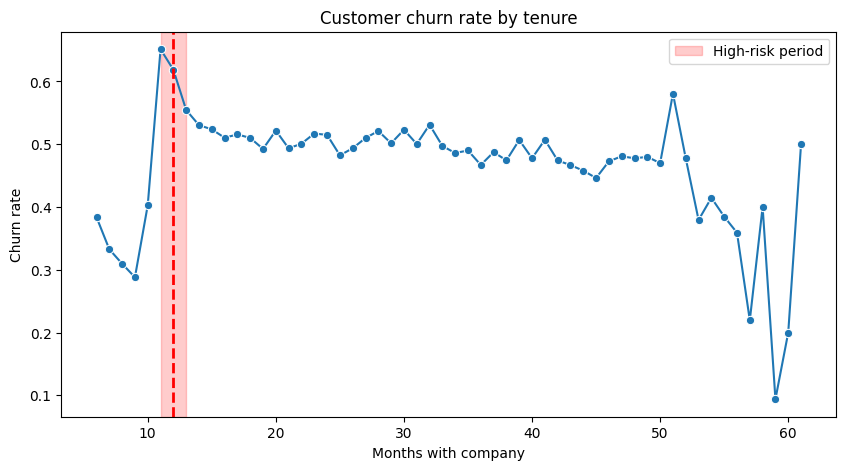

In [11]:
churn_by_month = (
    df.groupby("months")["churn"]
      .mean()
)

plt.figure(figsize=(10,5))

sns.lineplot(
    x=churn_by_month.index,
    y=churn_by_month.values,
    marker="o"
)

plt.axvspan(11, 13, color='red', alpha=0.2,
            label='High-risk period')

plt.axvline(
    x=12,
    color='red',
    linestyle='--',
    linewidth=2
)


plt.xlabel("Months with company")
plt.ylabel("Churn rate")
plt.title("Customer churn rate by tenure")
plt.legend()

plt.show()

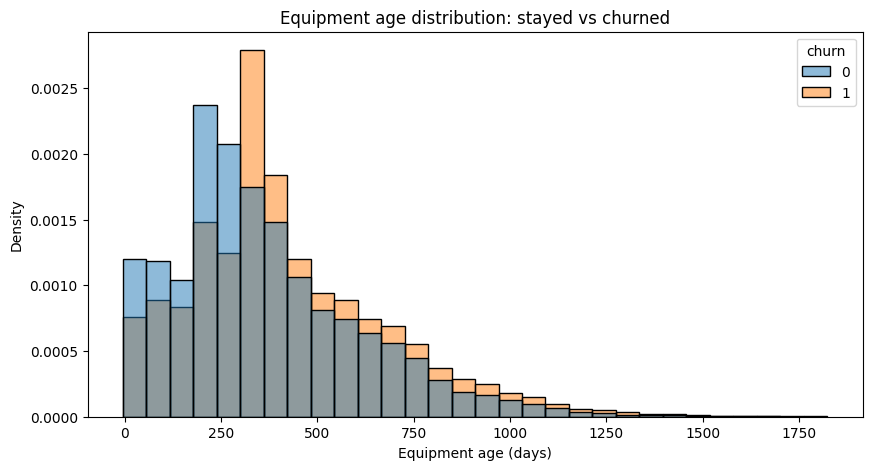

In [12]:
plt.figure(figsize=(10,5))

sns.histplot(
    data=df,
    x='eqpdays',
    hue='churn',
    bins=30,
    stat='density',
    common_norm=False,
    alpha=0.5
)

plt.xlabel('Equipment age (days)')
plt.ylabel('Density')
plt.title('Equipment age distribution: stayed vs churned')

plt.show()

# **4. Preprocessing and CatBoost model**

0:	test: 0.6161681	best: 0.6161681 (0)	total: 1.27s	remaining: 42m 19s
500:	test: 0.6834224	best: 0.6834224 (500)	total: 3m 41s	remaining: 11m 1s
1000:	test: 0.6922834	best: 0.6922909 (996)	total: 7m 15s	remaining: 7m 15s
1500:	test: 0.6952759	best: 0.6953328 (1471)	total: 10m 55s	remaining: 3m 38s
1999:	test: 0.6962486	best: 0.6962616 (1998)	total: 14m 29s	remaining: 0us

bestTest = 0.6962616357
bestIteration = 1998

Shrink model to first 1999 iterations.
              precision    recall  f1-score   support

           0       0.64      0.63      0.64     10088
           1       0.63      0.65      0.64      9912

    accuracy                           0.64     20000
   macro avg       0.64      0.64      0.64     20000
weighted avg       0.64      0.64      0.64     20000

[[6354 3734]
 [3511 6401]]
ROC-AUC: 0.6937818864692882


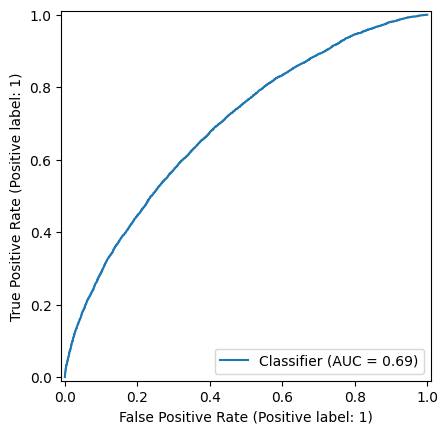

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay
from catboost import CatBoostClassifier

# Copy customers id for later use
customer_ids = df["Customer_ID"].copy()

# Drop columns with >30% of missing data
threshold = 0.3 * len(df)
cols_to_drop = df.columns[df.isnull().sum() > threshold]
df = df.drop(columns=cols_to_drop)

# Drop unnecessary columns
df = df.drop(columns=["Customer_ID", "ethnic"])

# Separated features and target
X = df.drop(columns=["churn"])
y = df["churn"]


cat_cols = X.select_dtypes(include="object").columns

for col in cat_cols:
  X[col] = X[col].fillna("Unknown")

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42
)

cat_features = X_train.select_dtypes(include="object").columns.tolist()

# Instantiate the model
model_cb = CatBoostClassifier(
    iterations=2000,
    learning_rate=0.02,
    depth=8,
    l2_leaf_reg=5,
    loss_function="Logloss",
    verbose=500,
    eval_metric="AUC",
    random_seed=42,
    thread_count=-1
)

# Train the model
model_cb.fit(
    X_train, y_train,
    cat_features=cat_features,
    early_stopping_rounds=100,
    eval_set=(X_val, y_val)
)

# Do predictions
y_pred = model_cb.predict(X_test)
y_prob = model_cb.predict_proba(X_test)[:, 1]

# Show results
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
RocCurveDisplay.from_predictions(y_test, y_prob)

In [14]:

# After making predictions on the test set
results = pd.DataFrame({
    "Customer_ID": customer_ids.loc[X_test.index],
    "Churn Probability": y_prob,
    "Prediction": y_pred
})


results["Prediction"] = results["Prediction"].map({
    0: "Stay",
    1: "Churn"
})

results["Churn Probability"] = (
    results["Churn Probability"] * 100
).round(1).astype(str) + "%"

results.head(6)

,Customer_ID,Churn Probability,Prediction
72528,1072529,72.5%,Churn
61418,1061419,70.9%,Churn
76571,1076572,14.5%,Stay
23239,1023240,39.0%,Stay
94364,1094365,27.5%,Stay
39162,1039163,54.8%,Churn


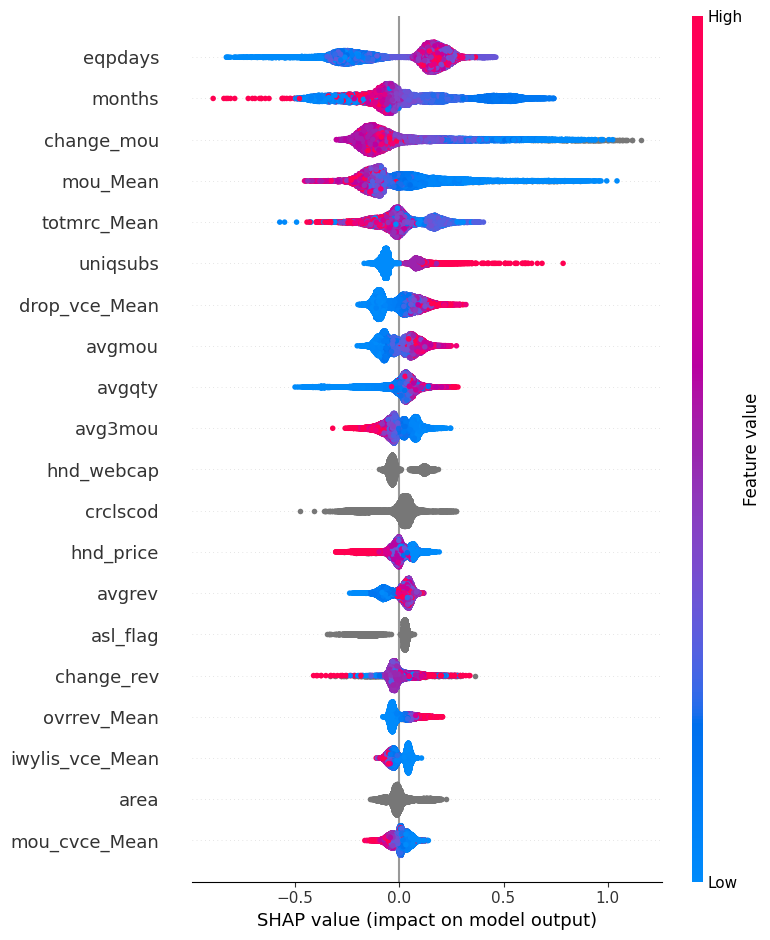

In [15]:
import shap

explainer = shap.TreeExplainer(model_cb)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test)

In [16]:
importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": model_cb.feature_importances_
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

importance.head(20)

,feature,importance
48,months,6.349314
90,eqpdays,6.068689
9,change_mou,5.828364
2,totmrc_Mean,4.403248
1,mou_Mean,4.025478
10,change_rev,3.180756
52,crclscod,2.576921
73,hnd_price,2.286368
62,avgqty,2.282059
11,drop_vce_Mean,2.156105
